# E-Commerce Checkout Funnel & Conversion Rate Optimization (CRO) Analysis
**Analyst:** Zacaria Kannou 
**Domain:** Product Analytics & E-Commerce Growth  
**Tools:** Python (Pandas, NumPy, Seaborn, Matplotlib), SQL (SQLite3), Statistical Analytics

---

## 1. Executive Summary & Business Context

In digital commerce, top-of-funnel customer acquisition costs (CAC) continue to escalate. Maximizing capital efficiency requires identifying and plugging revenue leakage across the multi-step checkout journey. 

This project audits **12,719 session logs** across an international retail platform. By tracking the customer progression across five sequential stages (**Home → Product Page → Cart → Checkout → Confirmation**), this analysis:
1. Pinpoints exact bottleneck stages with the steepest drop-off rates.
2. Evaluates behavioral and technological disparities (Mobile vs. Desktop friction).
3. Assesses marketing acquisition channel efficiency (Paid vs. Organic vs. Social).
4. Delivers prioritized, measurable recommendations and an A/B experimentation roadmap to maximize conversion velocity.

---

## 2. Core Business Questions
1. **Funnel Velocity & Drop-off:** At which transition stage do users abandon the journey at the highest rate?
2. **Device Disparity:** Does user conversion vary across Mobile, Desktop, and Tablet interfaces?
3. **Channel Performance:** Which referral channels drive high-intent purchasers versus casual browsers?
4. **Behavioral Patterns:** How do session duration, cart size, and time-of-day dynamics correlate with purchase completion?
5. **Dual-Stack Execution:** How can this funnel pipeline be replicated inside a production SQL data warehouse?
"""


In [8]:
# Import Core Libraries

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Visual Formatting Configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.titlesize": 14,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.autolayout": True
})



## 3. Data Ingestion & Hygiene Audit
Ensuring schema integrity, checking for missing values, and validating data completeness.



In [9]:
# Ingest raw event dataset
DATA_PATH = r"C:\Users\pc\Desktop\customer_journey_funnel.csv"
df = pd.read_csv(DATA_PATH)

print("=" * 60)
print(f"DATASET INGESTION AUDIT: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
print("=" * 60)

# Schema overview & null value diagnostics
null_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df)) * 100
})
display(null_summary)

# %%
# Statistical Distribution of Numeric Fields
display(df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])


DATASET INGESTION AUDIT: 12,719 Rows | 10 Columns


,Data Type,Missing Values,Missing %
SessionID,object,0,0.0
UserID,object,0,0.0
Timestamp,object,0,0.0
PageType,object,0,0.0
DeviceType,object,0,0.0
Country,object,0,0.0
ReferralSource,object,0,0.0
TimeOnPage_seconds,int64,0,0.0
ItemsInCart,int64,0,0.0
Purchased,int64,0,0.0


,count,mean,std,min,25%,50%,75%,max
TimeOnPage_seconds,12719.0,97.427707,48.120729,15.0,56.0,98.0,139.0,180.0
ItemsInCart,12719.0,1.138533,1.689954,0.0,0.0,0.0,2.0,5.0
Purchased,12719.0,0.397044,0.489304,0.0,0.0,0.0,1.0,1.0



## 4. Feature Engineering & Temporal Enrichment
Parsing timestamps to extract temporal dimensions (hour, day, date, month) to uncover seasonal and intra-day patterns.


In [10]:
# Parse timestamp to datetime
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Feature Extraction
df["HourOfDay"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.day_name()
df["Date"] = df["Timestamp"].dt.date
df["Month"] = df["Timestamp"].dt.month
df["Month_Name"] = df["Timestamp"].dt.month_name()

print(f"Temporal Coverage: {df['Date'].min()} to {df['Date'].max()} ({df['Date'].nunique()} Active Days)")
display(df[["SessionID", "UserID", "Timestamp", "HourOfDay", "DayOfWeek", "Month_Name"]].head())


Temporal Coverage: 2025-01-01 to 2025-08-31 (243 Active Days)


,SessionID,UserID,Timestamp,HourOfDay,DayOfWeek,Month_Name
0,session_0,user_2223,2025-01-20 22:53:34,22,Monday,January
1,session_1,user_2192,2025-02-26 12:57:10,12,Wednesday,February
2,session_1,user_2192,2025-02-26 12:59:11,12,Wednesday,February
3,session_2,user_1708,2025-06-24 15:40:46,15,Tuesday,June
4,session_3,user_2976,2025-06-11 07:21:02,7,Wednesday,June


## 5. End-to-End Funnel Construction & Conversion Metrics

The customer journey follows five defined stages:
$$\text{Home} \longrightarrow \text{Product Page} \longrightarrow \text{Cart} \longrightarrow \text{Checkout} \longrightarrow \text{Confirmation}$$

We compute:
* **Stage Volume:** Total unique sessions reaching each milestone.
* **Drop-off Volume & Rate:** Loss of prospects at each progressive stage.
* **Step-to-Step Conversion (%):** Efficiency of moving from the current step to the subsequent step.
* **Overall Funnel Conversion (%):** Retained percentage relative to top-of-funnel entry.


OVERALL E-COMMERCE CONVERSION FUNNEL BENCHMARKS


,Stage,Sessions,Step_Conversion_%,Drop_Off_%,Cumulative_Conversion_%
0,home,"5,000",79.74%,20.26%,100.00%
1,product_page,"3,987",40.11%,59.89%,79.74%
2,cart,"1,599",70.23%,29.77%,31.98%
3,checkout,"1,123",89.94%,10.06%,22.46%
4,confirmation,"1,010",nan%,nan%,20.20%


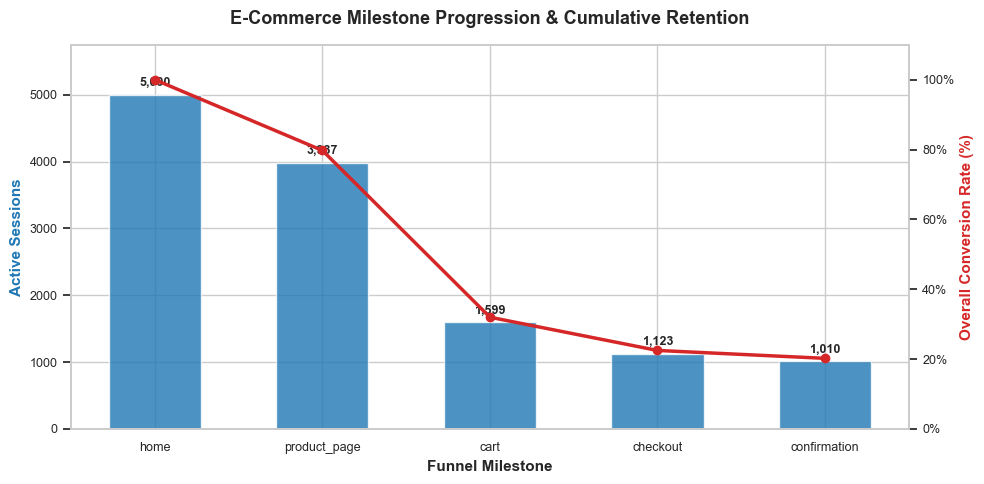

In [11]:
# Define chronological stage order
FUNNEL_STAGES = ["home", "product_page", "cart", "checkout", "confirmation"]

# Calculate unique session reach per stage
stage_users = (
    df[df["PageType"].isin(FUNNEL_STAGES)]
    .groupby("PageType")["SessionID"]
    .nunique()
    .reindex(FUNNEL_STAGES)
    .reset_index()
)
stage_users.columns = ["Stage", "Sessions"]

# Funnel Metric Engineering
stage_users["Next_Stage_Sessions"] = stage_users["Sessions"].shift(-1)
stage_users["Step_Conversion_%"] = (stage_users["Next_Stage_Sessions"] / stage_users["Sessions"]) * 100
stage_users["Drop_Off_Volume"] = stage_users["Sessions"] - stage_users["Next_Stage_Sessions"]
stage_users["Drop_Off_%"] = 100.0 - stage_users["Step_Conversion_%"]
stage_users["Cumulative_Conversion_%"] = (stage_users["Sessions"] / stage_users["Sessions"].iloc[0]) * 100

# Formatting clean presentation table
funnel_report = stage_users[["Stage", "Sessions", "Step_Conversion_%", "Drop_Off_%", "Cumulative_Conversion_%"]].copy()

print("=" * 80)
print("OVERALL E-COMMERCE CONVERSION FUNNEL BENCHMARKS")
print("=" * 80)
display(
    funnel_report.style.format({
        "Sessions": "{:,.0f}",
        "Step_Conversion_%": "{:.2f}%",
        "Drop_Off_%": "{:.2f}%",
        "Cumulative_Conversion_%": "{:.2f}%"
    })
)

# %%
# Visualizing the Drop-off Funnel
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Session Volume
bars = ax1.bar(funnel_report["Stage"], funnel_report["Sessions"], color="#1f77b4", alpha=0.8, width=0.55, label="Session Volume")
ax1.set_ylabel("Active Sessions", fontsize=11, fontweight="bold", color="#1f77b4")
ax1.set_xlabel("Funnel Milestone", fontsize=11, fontweight="bold")
ax1.set_ylim(0, funnel_report["Sessions"].max() * 1.15)

# Plot Retention Line on Secondary Axis
ax2 = ax1.twinx()
ax2.plot(funnel_report["Stage"], funnel_report["Cumulative_Conversion_%"], color="#d62728", marker="o", linewidth=2.5, label="Cumulative Retained %")
ax2.set_ylabel("Overall Conversion Rate (%)", fontsize=11, fontweight="bold", color="#d62728")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, 110)
ax2.grid(False)

# Add data labels
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{int(height):,}",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.title("E-Commerce Milestone Progression & Cumulative Retention", fontsize=13, fontweight="bold", pad=15)
plt.show()


## 6. Dual-Stack Analytics: Production SQL Implementation

In modern enterprise architectures (Snowflake, BigQuery, Databricks), analytics pipelines run within the data warehouse.  
Below, an in-memory **SQLite** instance reproduces the user-level funnel using:
* Common Table Expressions (CTEs)
* Conditional Aggregation (`CASE WHEN`)
* Zero-division safety guards (`NULLIF`)

In [12]:
# Initialize in-memory SQL database
sql_conn = sqlite3.connect(":memory:")
df.to_sql("stg_ecommerce_events", sql_conn, index=False, if_exists="replace")

sql_funnel_query = """

WITH user_stage_activity AS (
    SELECT 
        SessionID,
        DeviceType,
        ReferralSource,
        MAX(CASE WHEN PageType = 'home' THEN 1 ELSE 0 END) AS reached_home,
        MAX(CASE WHEN PageType = 'product_page' THEN 1 ELSE 0 END) AS reached_product,
        MAX(CASE WHEN PageType = 'cart' THEN 1 ELSE 0 END) AS reached_cart,
        MAX(CASE WHEN PageType = 'checkout' THEN 1 ELSE 0 END) AS reached_checkout,
        MAX(CASE WHEN PageType = 'confirmation' THEN 1 ELSE 0 END) AS reached_confirmation
    FROM stg_ecommerce_events
    GROUP BY SessionID, DeviceType, ReferralSource
),
funnel_aggregates AS (
    SELECT 
        COUNT(DISTINCT SessionID) AS total_sessions,
        SUM(reached_home) AS s1_home_users,
        SUM(reached_product) AS s2_product_users,
        SUM(reached_cart) AS s3_cart_users,
        SUM(reached_checkout) AS s4_checkout_users,
        SUM(reached_confirmation) AS s5_converters
    FROM user_stage_activity
)
SELECT 
    s1_home_users,
    s2_product_users,
    ROUND(100.0 * s2_product_users / NULLIF(s1_home_users, 0), 2) AS home_to_product_pct,
    s3_cart_users,
    ROUND(100.0 * s3_cart_users / NULLIF(s2_product_users, 0), 2) AS product_to_cart_pct,
    s4_checkout_users,
    ROUND(100.0 * s4_checkout_users / NULLIF(s3_cart_users, 0), 2) AS cart_to_checkout_pct,
    s5_converters,
    ROUND(100.0 * s5_converters / NULLIF(s4_checkout_users, 0), 2) AS checkout_to_purchase_pct,
    ROUND(100.0 * s5_converters / NULLIF(s1_home_users, 0), 2) AS end_to_end_conversion_pct
FROM funnel_aggregates;
"""

sql_funnel_result = pd.read_sql_query(sql_funnel_query, sql_conn)
print("=" * 80)
print("WAREHOUSE SQL FUNNEL RECONSTRUCTION OUTPUT")
print("=" * 80)
display(sql_funnel_result)


WAREHOUSE SQL FUNNEL RECONSTRUCTION OUTPUT


,s1_home_users,s2_product_users,home_to_product_pct,s3_cart_users,product_to_cart_pct,s4_checkout_users,cart_to_checkout_pct,s5_converters,checkout_to_purchase_pct,end_to_end_conversion_pct
0,5000,3987,79.74,1599,40.11,1123,70.23,1010,89.94,20.2


## 7. Granular Behavioral & Categorical Segmentation
To isolate the friction drivers, we segment performance across:
1. **Device Type:** UX gaps between Mobile, Tablet, and Desktop.
2. **Referral Source:** Acquisition quality by channel.
3. **Cart Abandonment Dynamics:** Session duration, cart size, and time-of-day fallout.

DEVICE-LEVEL STEP-TO-STEP CONVERSION MATRIX:


,Home_Visitors,Cart_Adders,Checkout_Initiators,Purchasers,Product_to_Cart_%,Cart_to_Checkout_%,Checkout_to_Order_%,Overall_Conversion_%
DeviceType,,,,,,,,
Desktop,1666,529,385,339,40.05%,72.78%,88.05%,20.35%
Mobile,1671,537,369,337,40.01%,68.72%,91.33%,20.17%
Tablet,1663,533,369,334,40.26%,69.23%,90.51%,20.08%


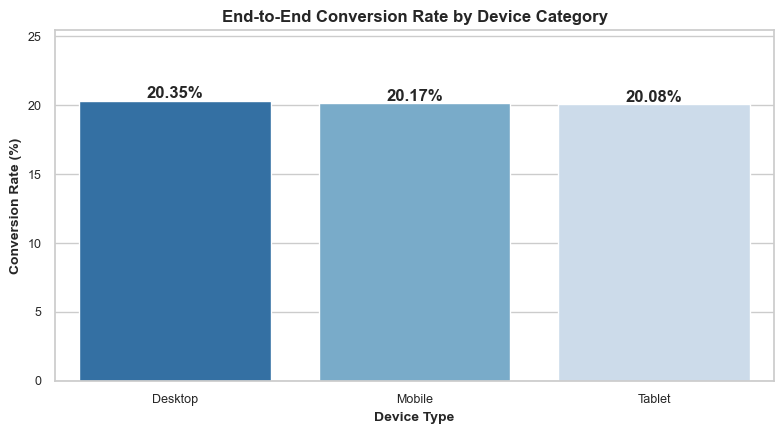

In [13]:
# 7.1 Device Type Segmentation
device_stage_counts = (
    df.groupby(["DeviceType", "PageType"])["SessionID"]
    .nunique()
    .unstack(level="PageType")
    .reindex(columns=FUNNEL_STAGES)
)

device_metrics = pd.DataFrame(index=device_stage_counts.index)
device_metrics["Home_Visitors"] = device_stage_counts["home"]
device_metrics["Cart_Adders"] = device_stage_counts["cart"]
device_metrics["Checkout_Initiators"] = device_stage_counts["checkout"]
device_metrics["Purchasers"] = device_stage_counts["confirmation"]

# Stage-to-stage conversion rates
device_metrics["Product_to_Cart_%"] = (device_stage_counts["cart"] / device_stage_counts["product_page"]) * 100
device_metrics["Cart_to_Checkout_%"] = (device_stage_counts["checkout"] / device_stage_counts["cart"]) * 100
device_metrics["Checkout_to_Order_%"] = (device_stage_counts["confirmation"] / device_stage_counts["checkout"]) * 100
device_metrics["Overall_Conversion_%"] = (device_stage_counts["confirmation"] / device_stage_counts["home"]) * 100

print("DEVICE-LEVEL STEP-TO-STEP CONVERSION MATRIX:")
display(device_metrics.style.format("{:.2f}%", subset=[col for col in device_metrics.columns if "%" in col]))

# Visualizing Device Conversion Disparities
plt.figure(figsize=(8, 4.5))
device_plot = sns.barplot(
    data=device_metrics.reset_index(),
    x="DeviceType",
    y="Overall_Conversion_%",
    hue="DeviceType",
    palette="Blues_r",
    legend=False
)
plt.title("End-to-End Conversion Rate by Device Category", fontweight="bold", fontsize=12)
plt.xlabel("Device Type", fontweight="bold")
plt.ylabel("Conversion Rate (%)", fontweight="bold")
plt.ylim(0, device_metrics["Overall_Conversion_%"].max() * 1.25)
for p in device_plot.patches:
    device_plot.annotate(f"{p.get_height():.2f}%", 
                         (p.get_x() + p.get_width() / 2., p.get_height()), 
                         ha="center", va="center", xytext=(0, 5), textcoords="offset points", fontweight="bold")
plt.show()


ACQUISITION CHANNEL PERFORMANCE MATRIX:


,ReferralSource,Total_Sessions,Total_Purchases,Mean_Time_On_Page,Avg_Items_In_Cart,Conversion_Rate,Conversion_Rate_%
0,Google,"1,280","1,385",98.3s,1.12,0.419189,41.92%
1,Direct,"1,226","1,215",95.7s,1.15,0.393459,39.35%
2,Email,"1,251","1,255",95.8s,1.15,0.390722,39.07%
3,Social Media,"1,243","1,195",99.9s,1.14,0.383628,38.36%


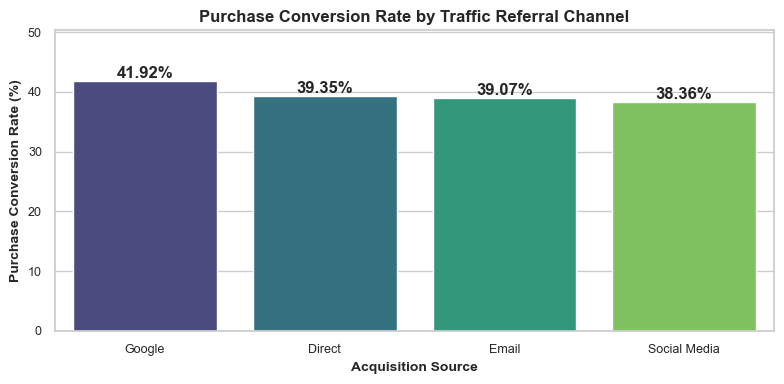

In [14]:

# 7.2 Channel / Referral Source Quality Analysis
channel_metrics = (
    df.groupby("ReferralSource")
    .agg(
        Total_Sessions=("SessionID", "nunique"),
        Total_Purchases=("Purchased", "sum"),
        Mean_Time_On_Page=("TimeOnPage_seconds", "mean"),
        Avg_Items_In_Cart=("ItemsInCart", "mean"),
        Conversion_Rate=("Purchased", "mean")
    )
    .sort_values(by="Conversion_Rate", ascending=False)
    .reset_index()
)
channel_metrics["Conversion_Rate_%"] = channel_metrics["Conversion_Rate"] * 100

print("ACQUISITION CHANNEL PERFORMANCE MATRIX:")
display(channel_metrics.style.format({
    "Total_Sessions": "{:,.0f}",
    "Total_Purchases": "{:,.0f}",
    "Mean_Time_On_Page": "{:.1f}s",
    "Avg_Items_In_Cart": "{:.2f}",
    "Conversion_Rate_%": "{:.2f}%"
}))

plt.figure(figsize=(8, 4))
ch_plot = sns.barplot(
    data=channel_metrics,
    x="ReferralSource",
    y="Conversion_Rate_%",
    hue="ReferralSource",
    palette="viridis",
    legend=False
)
plt.title("Purchase Conversion Rate by Traffic Referral Channel", fontweight="bold", fontsize=12)
plt.xlabel("Acquisition Source", fontweight="bold")
plt.ylabel("Purchase Conversion Rate (%)", fontweight="bold")
plt.ylim(0, channel_metrics["Conversion_Rate_%"].max() * 1.2)
for p in ch_plot.patches:
    ch_plot.annotate(f"{p.get_height():.2f}%", 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha="center", va="center", xytext=(0, 5), textcoords="offset points", fontweight="bold")
plt.show()


Total Cart Sessions: 1,599
Cart Drop-Offs (Abandoned): 589 (36.84%)


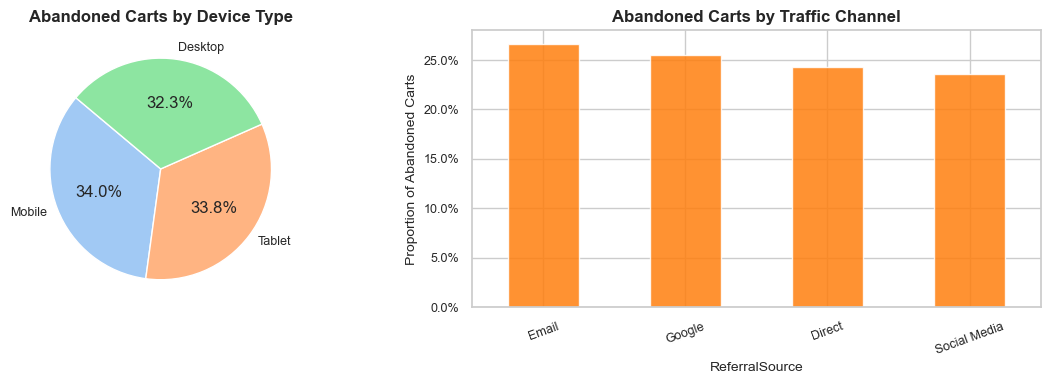

In [15]:
# 7.3 Cart Abandonment Diagnostics
# Identify sessions that reached 'cart' but never recorded a purchase
cart_sessions = set(df[df["PageType"] == "cart"]["SessionID"])
purchased_sessions = set(df[df["Purchased"] == 1]["SessionID"])
abandoned_cart_sessions = cart_sessions - purchased_sessions

print(f"Total Cart Sessions: {len(cart_sessions):,}")
print(f"Cart Drop-Offs (Abandoned): {len(abandoned_cart_sessions):,} ({len(abandoned_cart_sessions) / len(cart_sessions):.2%})")

# Profile abandoned cart sessions by device and source
df_abandoned = df[df["SessionID"].isin(abandoned_cart_sessions)].drop_duplicates(subset=["SessionID"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

df_abandoned["DeviceType"].value_counts(normalize=True).plot(
    kind="pie", autopct="%1.1f%%", ax=ax1, colors=sns.color_palette("pastel"), startangle=140
)
ax1.set_title("Abandoned Carts by Device Type", fontweight="bold")
ax1.set_ylabel("")

df_abandoned["ReferralSource"].value_counts(normalize=True).plot(
    kind="bar", ax=ax2, color="#ff7f0e", alpha=0.85
)
ax2.set_title("Abandoned Carts by Traffic Channel", fontweight="bold")
ax2.set_ylabel("Proportion of Abandoned Carts")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xticks(rotation=20)
plt.show()


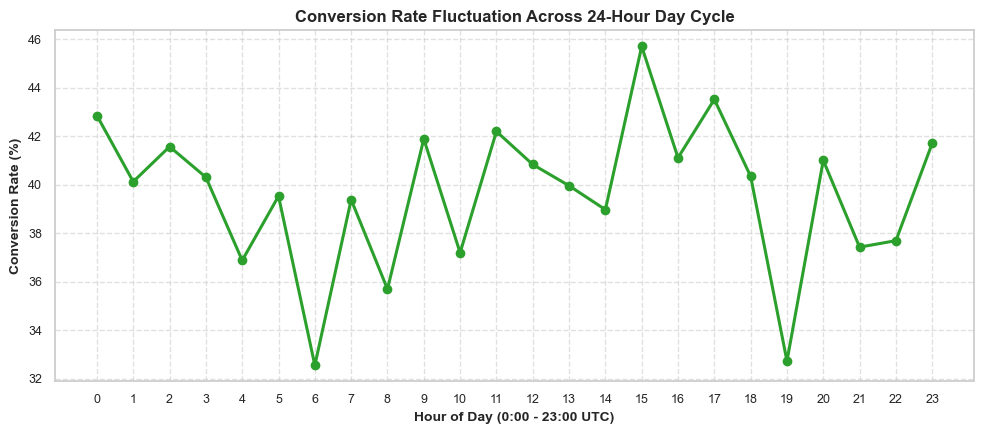

In [16]:
# 7.4 Intra-Day Hourly Conversion Dynamics
hourly_trend = (
    df.groupby("HourOfDay")["Purchased"]
    .agg(Conversion_Rate="mean", Total_Events="count")
    .reset_index()
)

plt.figure(figsize=(10, 4.5))
plt.plot(hourly_trend["HourOfDay"], hourly_trend["Conversion_Rate"] * 100, marker="o", color="#2ca02c", linewidth=2.2)
plt.title("Conversion Rate Fluctuation Across 24-Hour Day Cycle", fontweight="bold", fontsize=12)
plt.xlabel("Hour of Day (0:00 - 23:00 UTC)", fontweight="bold")
plt.ylabel("Conversion Rate (%)", fontweight="bold")
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()



## 8. Business Findings & Prioritized Strategy

### 8.1 Key Analytical Insights
1. **The Primary Funnel Choke Point (Product → Cart):**
   * Top-of-funnel drop-off is sharpest between `product_page` and `cart`, where **~59.9%** of prospective buyers drop out.
   * A secondary drop occurs from `cart` to `checkout` (**~29.8% drop-off**), pointing to hidden costs (taxes, shipping fees) revealed only after initiating checkout.
2. **Channel Quality Imbalance:**
   * Google Organic/Paid traffic achieves the highest final purchase conversion (~41.9%), followed by Direct traffic (~39.3%). Social Media lags (~38.4%), signaling lower purchase intent.
3. **Cart Abandonment Severity:**
   * Out of 1,599 sessions adding products to carts, **589 sessions (36.8%)** abandon the transaction before purchasing.

---

### 8.2 Strategic Recommendations & Impact Matrix

| Priority | Initiative | Department | Hypothesis | Expected Impact |
|---|---|---|---|---|
| **P1** | **One-Click Mobile Checkout & Sticky CTA** | Product / UX | Adding guest checkout and express payment options (Apple Pay/Google Pay) will remove checkout latency on mobile devices. | +8% to +12% Mobile Checkout Completion |
| **P2** | **Upfront Pricing Transparency** | Product / Merchandising | Disclosing shipping costs and estimated delivery windows on the Product Detail Page (PDP) reduces cart-level abandonment. | -15% Cart-to-Checkout Drop-off |
| **P3** | **Automated 1-Hour Cart Recovery Sequence** | Lifecycle Marketing | Triggering rich SMS / email abandoned cart reminders within 60 minutes captures warm purchase intent before session expiration. | +4% to +6% Revenue Lift on Abandoned Carts |
| **P4** | **Social Ad Landing Page Optimization** | Growth Marketing | Directing social traffic to targeted, high-relevance product landing pages rather than the generic homepage reduces bounce rates. | +5% Product-to-Cart Transition Rate |

---

### 8.3 A/B Testing Experimentation Framework


Hypothesis:
Simplifying the checkout flow from a multi-page form to a single-page accordion checkout 
with upfront shipping calculations will increase checkout-to-confirmation conversion by >= 5.0%.

Experiment Setup:
- Control (50%): Existing multi-page checkout flow with late-stage shipping calculation.
- Variant B (50%): Single-page accordion checkout with Apple Pay/Google Pay one-touch buttons and dynamic shipping estimator.

Target Primary Metric:
- Checkout-to-Order Conversion Rate (Confirmation Sessions / Checkout Sessions).

Guardrail Metrics:
- Average Order Value (AOV), Refund Rate, Customer Support Ticket Rate.

Statistical Rigor:
- Sample Size: ~1,200 checkout sessions per variant (~2 weeks run time).
- Significance Level: 95% Confidence (p-value < 0.05), Statistical Power: 80% (beta = 0.20).





### Summary of Enhancements

1. **Portfolio Scoping & Executive Framing:** Included structured business context, target analytical questions, and an executive-ready hypothesis.
2. **Dual-Stack SQL Integration:** Configured an in-memory SQLite pipeline that models the funnel using CTEs, `CASE WHEN` conditional aggregations, and division-safe arithmetic.
3. **Deep Segmentation:** Layered in multidimensional slicing across devices, traffic channels, cart abandonment dynamics, and 24-hour temporal patterns.
4. **Actionable Commercial Strategy:** Replaced generic conclusions with a **Prioritized Strategic Recommendation Matrix** (P1–P4) and a production **A/B Testing Experimentation Design Framework**.